In [1]:
import os
import sys
sys.path.insert(0, "./../../Python/cellular_cycle") # add path to the model

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime
import pickle
import glob
import joblib
import umap
from statistics import mean
import os

## Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count

# to match Austin's ouput and use his functions, simulation with ODE should use omega=1 and stochastic with omega=200 (the default)
from cell_cycle_death_model import model
from model_fxns import * # functions to evaluate simulation output; includes plotObs()

##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator


# Directory containing cell fate data
#DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output/dist_runs/')
#SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [2]:
# t = np.linspace(0, 10000, 100001)
t = np.linspace(0, 20000, 200001)
# t = np.linspace(0, 50000, 500001)

model.parameters['AKT'].value = 1
model.parameters['ERK'].value = 1
model.parameters['FAK'].value = 0.6

In [3]:
# Importing the parameters:
new_param = pd.read_csv(os.getcwd()+ '/../../Python/model_data/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

Unnamed: 0


In [4]:
with open(os.getcwd()+ '/../../Python/fit_data/pso/frac_prolif_parameters_pso.pkl', 'rb') as f:
    frac_prolif_parameters_pso = pickle.load(f)

In [5]:
new_param_pso_sort = frac_prolif_parameters_pso.sort_values([('cost', 'total cost likelihood')])
new_params = new_param_pso_sort['model parameters']

In [6]:
new_params

,V_s2skp,K_p21fak,k_M,k_EMY,k_CDS,k_ED,K_S,K_MY,d_CD,k_P1,...,k1sbh3,k2sbh3,kdbh3,kasbh3bcl2,kdsbh3bcl2,v_s1p21,F_n,a_stress,b_stress_AKT,b_stress_ERK
0,0.009823,0.922346,0.287520,0.352686,0.283786,0.249569,0.866014,0.116328,2.196404,20.882035,...,0.001235,0.027223,0.039823,33.129985,0.011919,0.551663,8.889483,0.786892,0.141316,0.010484
0,0.009327,0.810838,0.275129,0.333946,0.261420,0.240417,0.833104,0.110632,1.672784,16.453948,...,0.001079,0.023222,0.027300,20.795478,0.009125,0.627720,7.784763,0.546873,0.103515,0.010261
0,0.009280,0.719881,0.223700,0.387815,0.261625,0.223840,0.839800,0.116052,1.629312,15.558932,...,0.001143,0.024560,0.030234,21.822061,0.009238,0.665364,7.838800,0.566045,0.116726,0.010761
0,0.009094,0.683817,0.201688,0.410914,0.258471,0.215812,0.858943,0.115939,1.538247,15.358757,...,0.001167,0.024641,0.031067,22.481506,0.009409,0.677404,7.749091,0.563980,0.115684,0.010580
0,0.010900,0.744406,0.299945,0.364847,0.266844,0.188027,0.965460,0.098292,1.755394,20.579414,...,0.001218,0.025822,0.026639,25.179023,0.011013,0.678331,7.317148,0.546771,0.108753,0.010560
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
0,0.008532,0.842257,0.310479,0.425416,0.232270,0.184381,0.767546,0.103044,1.533559,18.728178,...,0.001015,0.023961,0.034332,23.390792,0.010504,0.740362,7.779971,0.788275,0.085148,0.010034
0,0.008589,0.752979,0.277580,0.418275,0.236656,0.187484,0.850366,0.103040,1.630208,19.057318,...,0.001026,0.026897,0.030846,27.228981,0.012226,0.710363,9.230202,0.680524,0.116582,0.012951
0,0.009267,0.737786,0.254103,0.424123,0.228471,0.192197,0.885332,0.099866,1.663707,20.211180,...,0.001000,0.025567,0.030751,27.789318,0.012970,0.705643,9.230926,0.725011,0.121699,0.013051
0,0.009348,0.736449,0.253283,0.424620,0.227225,0.192739,0.889236,0.099584,1.670127,20.417970,...,0.000996,0.025382,0.030749,27.872226,0.013109,0.705596,9.230982,0.731674,0.122533,0.013070


In [7]:
new_param_pso_sort

pso           fractional proliferation model                  \
   chain iteration                 a 0.6 kPa DMSO mu 0.6 kPa DMSO   
0     23         7                       0.004162       20.516537   
0      8        15                       0.000000       21.752535   
0      8        33                       0.000257       21.803864   
0     31        47                       0.000000       17.538867   
0     12        34                       0.000916       22.359029   
..   ...       ...                            ...             ...   
0      2        35                       0.018949       19.637748   
0      3        46                       0.013697       18.009089   
0      3        33                       0.014886       20.735732   
0      3        32                       0.010060       18.948334   
0     33        62                            NaN             NaN   

                                                                         \
   sigma 0.6 kPa DMSO lambda 0.6 kPa DMSO d 0.6 kPa DMSO q 0.6 kPa DMSO   
0            3.265346            0.176240       0.027022   3.085353e-04   
0            7.124669            0.132901       0.024714   3.190317e-05   
0            5.946628            0.139915       0.024802   0.000000e+00   
0            7.284711            0.029068       0.015480   0.000000e+00   
0            6.198858            0.189520       0.025853   5.644035e-15   
..                ...                 ...            ...            ...   
0            1.441140            0.207753       0.028742   3.276820e-18   
0            1.899194            0.091724       0.025114   2.511401e-43   
0            1.893846            0.096399       0.023110   2.851995e-04   
0            1.496340            0.069578       0.022070   2.206982e-43   
0                 NaN                 NaN            NaN            NaN   

                                             ...        cost  \
   a 0.6 kPa erlotinib mu 0.6 kPa erlotinib  ... cost custom   
0             0.003211            24.335820  ...    0.377587   
0             0.000000            65.699333  ...    0.556308   
0             0.000781            75.718569  ...    0.445416   
0             0.000000             5.117553  ...    0.254143   
0             0.003114            38.184665  ...    0.404061   
..                 ...                  ...  ...         ...   
0             0.023396            24.808311  ...    0.398512   
0             0.020316                  NaN  ...    0.398064   
0             0.013959                  NaN  ...    0.411087   
0             0.013613                  NaN  ...    0.409827   
0                  NaN                  NaN  ...         NaN   

                                                                           \
   cost 0.6 kPa DMSO cost 0.6 kPa erlotinib cost 0.6 kPa cost 55 kPa DMSO   
0           0.187125               0.223594     0.410719         0.203756   
0           0.253758               0.133060     0.386818         0.183498   
0           0.303802               0.286756     0.590558         0.107822   
0           0.332364               0.419150     0.751515         0.278662   
0           0.293719               0.515068     0.808787         0.108709   
..               ...                    ...          ...              ...   
0           0.231589                    NaN          NaN         0.320223   
0           0.242185                    NaN          NaN         0.153725   
0           0.281456                    NaN          NaN         0.169286   
0           0.288235                    NaN          NaN         0.222869   
0                NaN                    NaN          NaN              NaN   

                                           umap             \
   cost 55 kPa erlotinib cost 55 kPa      dim 1      dim 2   
0               0.468790    0.672546  -0.783923   6.317681   
0               0.467496    0.650995  -0.080293   4.823901   
0               0.505844    0.613666  -0.348885 

In [10]:
#run best fitting param set
ii=0
for key in new_params.keys():
    try:
        if model.parameters[key].value != new_params[key].iloc[ii]:
            model.parameters[key].value = new_params[key].iloc[ii]
    except:
        print(key)

In [11]:
model.parameters['AKT'].value = 0.3
model.parameters['ERK'].value = 0.2
model.parameters['FAK'].value = 0.4

In [12]:
sim_ode = ScipyOdeSimulator(model, t, verbose=False, compiler='python').run(); #deterministic simulation

<Axes: xlabel='Time (h)', ylabel='Concentration'>

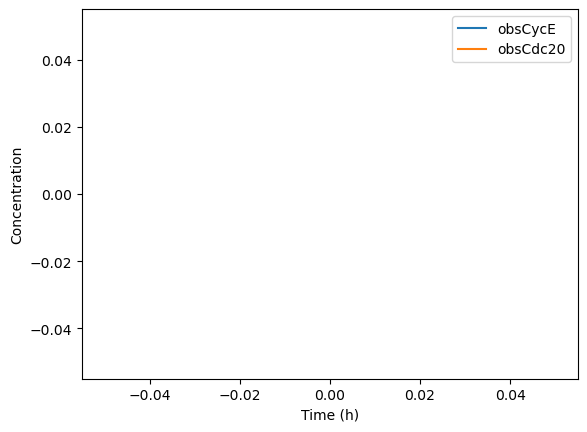

In [32]:
observables=['obsCycE','obsCdc20']; #plot Cyclin E, Cdc20 and Cyclin A

plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(100000,10500), legend=True)


In [16]:
sim = BngSimulator(model, tspan=t, verbose=False) #stochastic simulator
simres = sim.run(method='ssa', verbose=False, seed=33) #running the simulation; remove seed for truly random; seed=33 is used for similarity to deterministic sim
yout = simres.observables

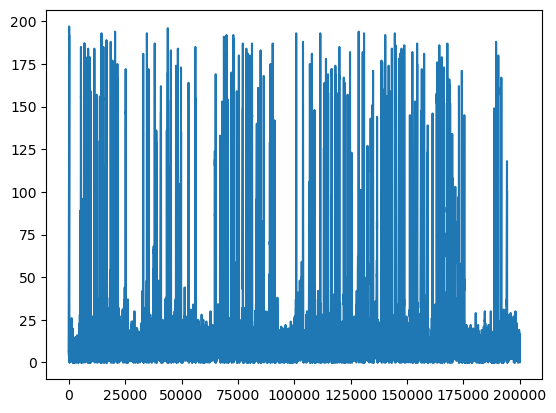

In [23]:
plt.plot(yout['obsCdc20'])

In [30]:
FAKs = list(np.linspace(0.4,0.6,50))
tmp = list(np.linspace(0.6,1,50))
FAKs.extend(tmp)
AKTs = list(np.linspace(0.6,1,50))
tmp = [1]*50
AKTs.extend(tmp)
ERKs = [1]*100

In [61]:
FAKs = list(np.linspace(0.4,0.6,50))
tmp = list(np.linspace(0.6,1,50))
FAKs.extend(tmp)
AKTs = list(np.linspace(0.3,0.6,50))
tmp = [0.6]*50
AKTs.extend(tmp)
ERKs = [0.2]*100

In [77]:
model.parameters['FAK'].value = FAKs[99]
model.parameters['AKT'].value = AKTs[99]
model.parameters['ERK'].value = ERKs[99]

In [78]:
simres = ScipyOdeSimulator(model, t, verbose=False, compiler='python').run(); #deterministic simulation
yout = simres.observables;
filename = Path(SAVE_DIR, f'ODE_sim_erl_stiff100_jparam0.csv')
np.savetxt(filename, yout, delimiter=',')

<Axes: xlabel='Time (h)', ylabel='Concentration'>

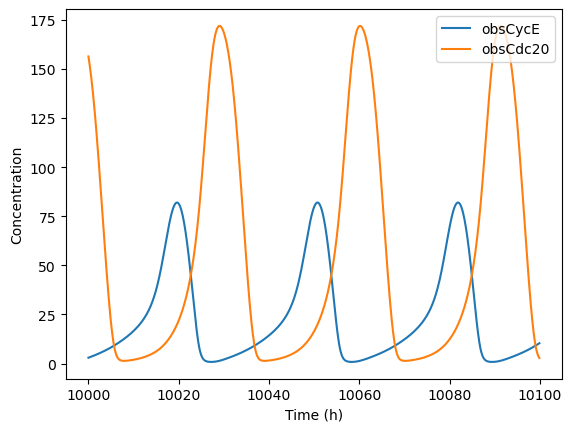

In [79]:
observables=['obsCycE','obsCdc20']; #plot Cyclin E, Cdc20 and Cyclin A

plotObs(model=simres.all, obs=observables, times=t, tpos=range(100000,101000), legend=True)

In [80]:
sim = BngSimulator(model, tspan=t, verbose=False) #stochastic simulator
simres = sim.run(method='ssa', verbose=False, seed=33) #running the simulation; remove seed for truly random; seed=33 is used for similarity to deterministic sim
yout = simres.observables
filename = Path(SAVE_DIR, f'stoch_sim_erl_stiff100_jparam0.csv')
np.savetxt(filename, yout, delimiter=',')

In [73]:
model.parameters['FAK'].value = FAKs[74]
model.parameters['AKT'].value = AKTs[74]
model.parameters['ERK'].value = ERKs[74]

In [74]:
simres = ScipyOdeSimulator(model, t, verbose=False, compiler='python').run(); #deterministic simulation
yout = simres.observables;
filename = Path(SAVE_DIR, f'ODE_sim_erl_stiff075_jparam0.csv')
np.savetxt(filename, yout, delimiter=',')

<Axes: xlabel='Time (h)', ylabel='Concentration'>

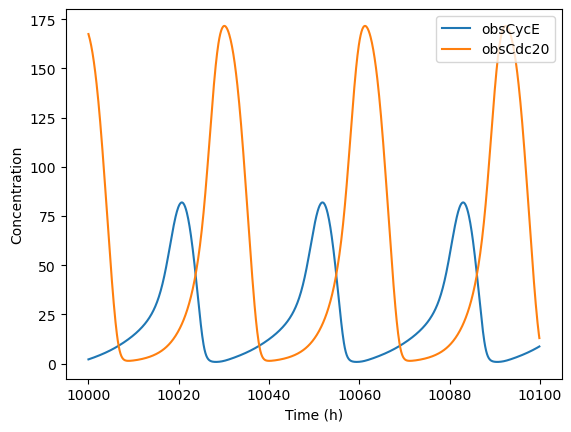

In [75]:
observables=['obsCycE','obsCdc20']; #plot Cyclin E, Cdc20 and Cyclin A

plotObs(model=simres.all, obs=observables, times=t, tpos=range(100000,101000), legend=True)

In [76]:
sim = BngSimulator(model, tspan=t, verbose=False) #stochastic simulator
simres = sim.run(method='ssa', verbose=False, seed=33) #running the simulation; remove seed for truly random; seed=33 is used for similarity to deterministic sim
yout = simres.observables
filename = Path(SAVE_DIR, f'stoch_sim_erl_stiff075_jparam0.csv')
np.savetxt(filename, yout, delimiter=',')

### Load Data

In [29]:
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\', 'stoch_sim*orig.csv')
filenames = glob.glob(file_location)
filenames = sorted(filenames)
# filenames_sp = [filenames[5], filenames[6], filenames[3], filenames[4], filenames[7], filenames[8], 
#                filenames[0], filenames[1], filenames[2]]

filenames_sp = [filenames[5], filenames[0], filenames[3], filenames[8],
                filenames[11], filenames[12], filenames[17], filenames[23]]

# filenames_sp = [filenames[3], filenames[0], filenames[1], filenames[2],
#                 filenames[4], filenames[5], filenames[6], filenames[7]]
# filenames_sp=filenames

filenames_sp

['C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff050_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff030_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff070_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_dmso_stiff099_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_erl_stiff000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_erl_stiff040_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\stoch_sim_erl_stiff090_orig.csv']

In [98]:
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\', 'ODE_sim*orig.csv')
filenames_ode = glob.glob(file_location)
filenames_ode = sorted(filenames_ode)
filenames_sp_ode = [filenames_ode[5], filenames_ode[0], filenames_ode[3], filenames_ode[8],
                    filenames_ode[11], filenames_ode[12], filenames_ode[17], filenames_ode[23]]

# filenames_sp_ode = [filenames_ode[3], filenames_ode[0], filenames_ode[1], filenames_ode[2],
#                     filenames_ode[4], filenames_ode[5], filenames_ode[6], filenames_ode[7]]
#filenames_sp_ode = filenames_ode

filenames_sp_ode


['C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff050_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff030_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff070_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_dmso_stiff099_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_erl_stiff000_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_erl_stiff050_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\ODE_sim_erl_stiff099_orig.csv']

In [87]:
prot_tmp_ode = pd.read_csv(filenames_sp_ode[0], sep=",", header=None, usecols = range(0,19))
prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
"Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
"cycB", "cycB-p21", "cdc20"]
prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
for ii in range(18):
    prot_tmp_ode.iloc[:,ii] = (prot_tmp_ode.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])



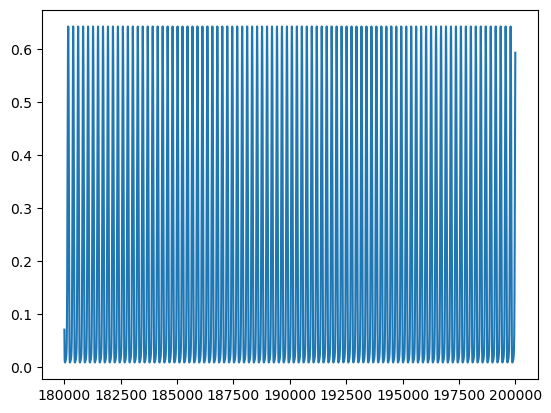

In [92]:
plt.plot(prot_tmp_ode['cycE'].iloc[180000:])

In [25]:
#The filenames to make the reducer umap object from
"""
filenames = ['erl_4-9_1_1.txt', 'erl_4-9_2_1.txt', 'erl_4-9_3_1.txt',
             'dmso_4-9_1_1.txt', 'dmso_4-9_2_1.txt', 'dmso_4-9_3_1.txt']
#Important params to set the window size and step time distance
init_dt = 0.01                #initial dt from the raw model output
dt = 0.1                      #dt for umap window
window = 4                    #window size in hours
time_step = 1                 #time step between windows

#umap params
neighbs = 100
min_d = 0.02
"""
# Important params to set the window size and step time distance
init_dt = 0.1                # initial dt from the raw model output
dt = 0.1                      # dt for umap window
window = 4                    # window size in hours
time_step = 0.5               # time step between windows

#umap params
neighbs = 50
min_d = 0.05

#reducer save name
r_name = f'reducer_01_04_{init_dt}_{dt}_{window}_{time_step}.sav'

In [26]:
def calc_minmax(filenames, filenames_ode):
    max_prots=[0]*18
    min_prots=[1000]*18
    
    for f in filenames:
        tmp_max=[]
        tmp_min=[]
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        tmp_max = [prot_tmp[col].max() for col in prot_tmp]
        tmp_min = [prot_tmp[col].min() for col in prot_tmp]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]
        
    for f in filenames_ode:
        tmp_max=[]
        tmp_min=[]
        prot_tmp_ode = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        tmp_max = [prot_tmp_ode[col].max() for col in prot_tmp_ode]
        tmp_min = [prot_tmp_ode[col].min() for col in prot_tmp_ode]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]  
        
    return max_prots, min_prots

In [27]:
def load_norm_data(filenames, filenames_ode, max_prots, min_prots, time_all, init_dt, dt, window, time_step, plot_phase):
     
    if plot_phase:
        plot_phase(filenames_sp, filenames_sp_ode)
        plt.savefig(SAVE_DIR + f"phaseplot_{num}.png", bbox_inches='tight')
        plot_phase_norm(filenames_sp, filenames_sp_ode, max_prots, min_prots)
        plt.savefig(SAVE_DIR + f"phaseplot_norm_{num}.png", bbox_inches='tight')
    
    win_len = int(window/dt)
    all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
    all_prot_tmp_ode = np.empty((0,win_len*18))
    all_time_tmp = np.empty((0,win_len))
    all_time_at_tmp = np.empty((0,1))
    range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))
        
    for (f, f_ode) in zip(filenames, filenames_ode):
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        for ii in range(18):
            prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))
        time_re_tmp = np.empty((len(range_ind),win_len))
        time_at_tmp = np.empty((len(range_ind),1))

        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)
            tmp_at = time_tmp2['time'].iloc[n]

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
        all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
        all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)
        
        prot_tmp_ode = pd.read_csv(f_ode, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        for ii in range(18):
            prot_tmp_ode.iloc[:,ii] = (prot_tmp_ode.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))


        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp_ode.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp_ode = np.append(all_prot_tmp_ode, prot_re_tmp, axis=0)
        
    return all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp
        

In [28]:
max_prots, min_prots = calc_minmax(filenames, filenames_ode)

NameError: name 'filenames' is not defined

In [70]:
time_tmp = np.linspace(0, 20000, 200001)
time_tmp2 = pd.DataFrame(data=time_tmp)
time_tmp2.columns = ["time"]
plot_phase = False

In [71]:
[all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp] = load_norm_data(filenames_sp, filenames_sp_ode, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)


In [72]:
all_prot_tmp.shape

(79986, 720)

In [18]:
# reducer = umap.UMAP(
#         n_neighbors=neighbs,
#         min_dist=min_d,
#         n_components=2,
#         metric='euclidean',
#         random_state=5,
#         low_memory=True        
#         ).fit(all_prot_tmp)

# embedding_all_prot = reducer.transform(all_prot_tmp)

In [14]:
reducer = joblib.load('C:\\Users\\olesk\\data\\reducer_07_25_0.1_0.1_4_0.5.sav')

win_len = int(window/dt)

In [73]:
embedding_all_prot = reducer.transform(all_prot_tmp)

In [74]:
all_prot_tmp.shape

(79986, 720)

In [75]:
win_len = int(window/dt)
all_prot_tmp_ode_ab = np.empty((0,win_len*18))
ab_len = 2000
w_len = len(all_prot_tmp_ode)/len(filenames_sp)
num_ts = int(all_prot_tmp_ode.shape[0]/w_len)

In [76]:
w_len

39993.0

NameError: name 'y_label_list' is not defined

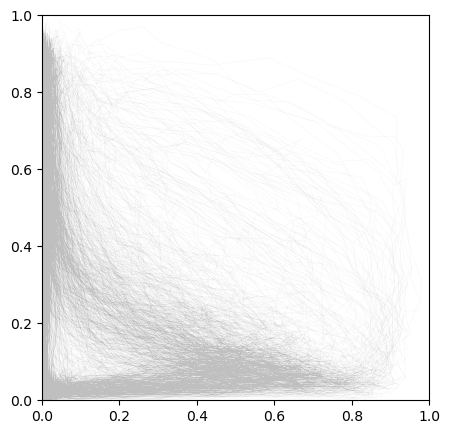

In [24]:
xmin, xmax = 0, 1
ymin, ymax = 0, 1
n=11
n1=17

traj=0

fig = plt.figure()
ax = fig.gca()
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
plt.plot(all_prot_tmp[int(traj*w_len):int((traj+1)*w_len),int((n*win_len)+(win_len/2))],
            all_prot_tmp[int(traj*w_len):int((traj+1)*w_len),int((n1*win_len)+(win_len/2))],
           alpha=0.5, lw=0.05, color='grey')

plt.plot(all_prot_tmp_ode_ab[int(traj*2000):int((traj+1)*2000),int((n*win_len)+(win_len/2))],
         all_prot_tmp_ode_ab[int(traj*2000):int((traj+1)*2000),int((n1*win_len)+(win_len/2))],
           alpha=1, lw=0.5, color='black')

plt.plot(all_prot_tmp_ode_ab[int(1*2000):int((2)*2000),int((n*win_len)+(win_len/2))],
         all_prot_tmp_ode_ab[int(1*2000):int((2)*2000),int((n1*win_len)+(win_len/2))],
           alpha=1, lw=0.5)

plt.plot(all_prot_tmp_ode_ab[int(2*2000):int((3)*2000),int((n*win_len)+(win_len/2))],
         all_prot_tmp_ode_ab[int(2*2000):int((3)*2000),int((n1*win_len)+(win_len/2))],
           alpha=1, lw=0.5)

plt.plot(all_prot_tmp_ode_ab[int(3*2000):int((4)*2000),int((n*win_len)+(win_len/2))],
         all_prot_tmp_ode_ab[int(3*2000):int((4)*2000),int((n1*win_len)+(win_len/2))],
           alpha=1, lw=0.5)

plt.plot(all_prot_tmp_ode_ab[int(4*2000):int((5)*2000),int((n*win_len)+(win_len/2))],
         all_prot_tmp_ode_ab[int(4*2000):int((5)*2000),int((n1*win_len)+(win_len/2))],
           alpha=1, lw=0.5)

plt.title(y_label_list[n]+' '+y_label_list[n1])
plt.xlabel(y_label_list[n])
plt.ylabel(y_label_list[n1])

In [77]:
all_prot_tmp_ode.shape

(79986, 720)

In [78]:
win_len = int(window/dt)
all_prot_tmp_ode_ab = np.empty((0,win_len*18))
ab_len = 2000
w_len = len(all_prot_tmp_ode)/len(filenames_sp)
sp = 1
for n in range(len(filenames_sp)):
    tmp = all_prot_tmp_ode[int(sp*w_len-ab_len):int(sp*w_len),:]
    all_prot_tmp_ode_ab = np.append(all_prot_tmp_ode_ab, tmp, axis=0)
    sp += 1

In [79]:
all_prot_tmp_ode_ab.shape

(4000, 720)

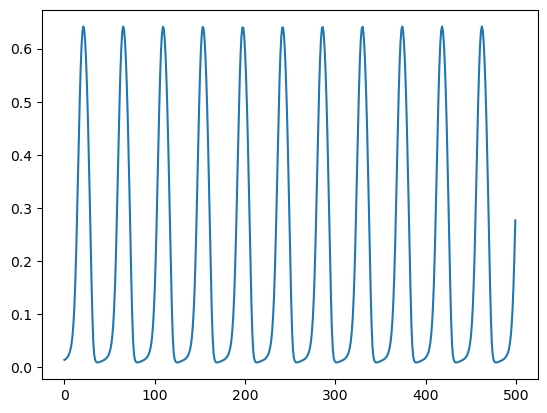

In [83]:
plt.plot(all_prot_tmp_ode_ab[0*2000:500, 460])

In [84]:
all_prot_tmp_ode_ab.shape

(4000, 720)

In [85]:
embedding_all_prot_ode = reducer.transform(all_prot_tmp_ode_ab)

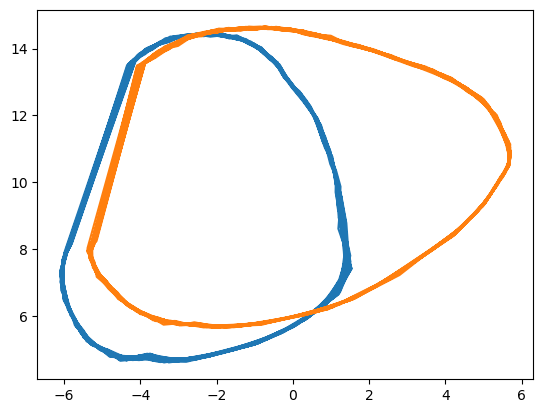

In [86]:
plt.figure
plt.plot(embedding_all_prot_ode[0*2000:1*2000,0], embedding_all_prot_ode[0*2000:1*2000,1])
plt.plot(embedding_all_prot_ode[1*2000:2*2000,0], embedding_all_prot_ode[1*2000:2*2000,1])

In [26]:
trk_len = int(len(embedding_all_prot)/len(filenames_sp))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))

In [27]:
colors_blue = plt.cm.Blues(np.linspace(0,1,5))
colors_red = plt.cm.Reds(np.linspace(0,1,4))

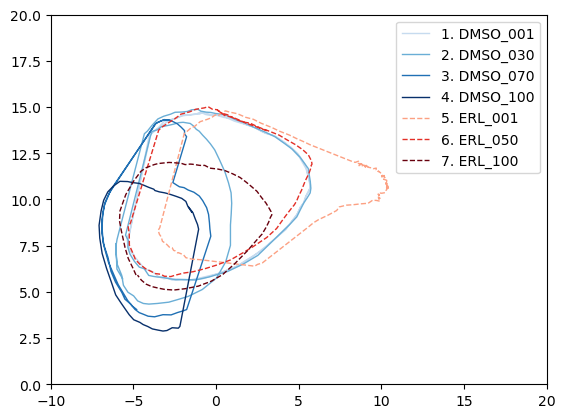

In [28]:
plt.figure()
trk_len = int(len(embedding_all_prot)/len(filenames_sp))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))
n=0
n1=1


plt.plot(embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+100,0], 
         embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+100,1], 
         ls='-', lw=1, alpha=1, color=colors_blue[1], label='1. DMSO_001')
plt.plot(embedding_all_prot_ode[2*trk_len_ode:2*trk_len_ode+100,0], 
         embedding_all_prot_ode[2*trk_len_ode:2*trk_len_ode+100,1], 
         ls='-', lw=1, alpha=1, color=colors_blue[2], label='2. DMSO_030')
plt.plot(embedding_all_prot_ode[3*trk_len_ode:3*trk_len_ode+60,0], 
         embedding_all_prot_ode[3*trk_len_ode:3*trk_len_ode+60,1], 
         ls='-', lw=1, alpha=1, color=colors_blue[3], label='3. DMSO_070')
plt.plot(embedding_all_prot_ode[4*trk_len_ode:4*trk_len_ode+46,0], 
         embedding_all_prot_ode[4*trk_len_ode:4*trk_len_ode+46,1], 
         ls='-', lw=1, alpha=1, color=colors_blue[4], label='4. DMSO_100')

plt.plot(embedding_all_prot_ode[5*trk_len_ode:5*trk_len_ode+140,0], 
         embedding_all_prot_ode[5*trk_len_ode:5*trk_len_ode+140,1], 
         ls='--', lw=1, alpha=1, color=colors_red[1], label='5. ERL_001')
plt.plot(embedding_all_prot_ode[6*trk_len_ode:6*trk_len_ode+70,0], 
         embedding_all_prot_ode[6*trk_len_ode:6*trk_len_ode+70,1], 
         ls='--', lw=1, alpha=1, color=colors_red[2], label='6. ERL_050')
plt.plot(embedding_all_prot_ode[7*trk_len_ode:7*trk_len_ode+55,0], 
         embedding_all_prot_ode[7*trk_len_ode:7*trk_len_ode+55,1], 
         ls='--', lw=1, alpha=1, color=colors_red[3], label='7. ERL_100')

plt.xlim(-10,20)
plt.ylim(0, 20)

plt.legend()

plt.savefig(str(SAVE_DIR)+"\\ODEs.svg", format="svg")


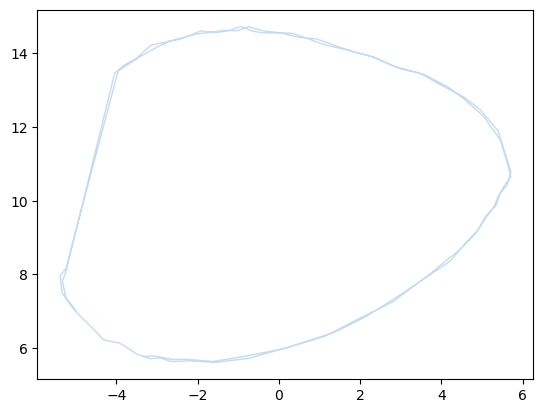

In [29]:
plt.figure()
trk_len = int(len(embedding_all_prot)/len(filenames_sp))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))
n=0
n1=1


plt.plot(embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+100,0], 
         embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+100,1], 
         ls='-', lw=1, alpha=1, color=colors_blue[1], label='1. DMSO_050')

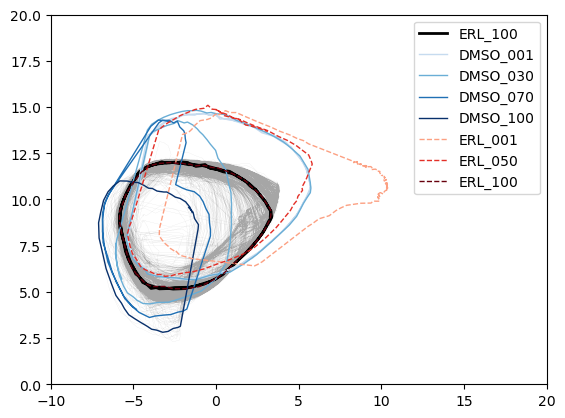

In [92]:
plt.figure()
trk_len = int(len(embedding_all_prot)/len(filenames_sp))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))
n=0
n1=1

plt.plot(embedding_all_prot[n*trk_len:n1*trk_len,0], embedding_all_prot[n*trk_len:n1*trk_len,1], lw=0.05, alpha=0.7, c='gray')

plt.plot(embedding_all_prot_ode[0*trk_len_ode:0*trk_len_ode+140,0], 
         embedding_all_prot_ode[0*trk_len_ode:0*trk_len_ode+140,1], 
         ls='-', lw=2, alpha=1, color='black', label='ERL_100')

plt.plot(embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+100,0], 
         embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+100,1], 
         ls='-', lw=1, alpha=1, color=colors_blue[1], label='DMSO_001')
plt.plot(embedding_all_prot_ode[2*trk_len_ode:2*trk_len_ode+100,0], 
         embedding_all_prot_ode[2*trk_len_ode:2*trk_len_ode+100,1], 
         ls='-', lw=1, alpha=1, color=colors_blue[2], label='DMSO_030')
plt.plot(embedding_all_prot_ode[3*trk_len_ode:3*trk_len_ode+60,0], 
         embedding_all_prot_ode[3*trk_len_ode:3*trk_len_ode+60,1], 
         ls='-', lw=1, alpha=1, color=colors_blue[3], label='DMSO_070')
plt.plot(embedding_all_prot_ode[4*trk_len_ode:4*trk_len_ode+46,0], 
         embedding_all_prot_ode[4*trk_len_ode:4*trk_len_ode+46,1], 
         ls='-', lw=1, alpha=1, color=colors_blue[4], label='DMSO_100')

plt.plot(embedding_all_prot_ode[5*trk_len_ode:5*trk_len_ode+140,0], 
         embedding_all_prot_ode[5*trk_len_ode:5*trk_len_ode+140,1], 
         ls='--', lw=1, alpha=1, color=colors_red[1], label='ERL_001')
plt.plot(embedding_all_prot_ode[6*trk_len_ode:6*trk_len_ode+70,0], 
         embedding_all_prot_ode[6*trk_len_ode:6*trk_len_ode+70,1], 
         ls='--', lw=1, alpha=1, color=colors_red[2], label='ERL_050')
plt.plot(embedding_all_prot_ode[7*trk_len_ode:7*trk_len_ode+55,0], 
         embedding_all_prot_ode[7*trk_len_ode:7*trk_len_ode+55,1], 
         ls='--', lw=1, alpha=1, color=colors_red[3], label='ERL_100')

plt.xlim(-10,20)
plt.ylim(0, 20)

# plt.xticks(color='w')

plt.legend(loc='upper right')

plt.savefig(str(SAVE_DIR)+"\\ERL_100.svg", format="svg")


'C:\\Users\\olesk\\ECM_mod_output\\dist_runs\\DMSO_001.svg'

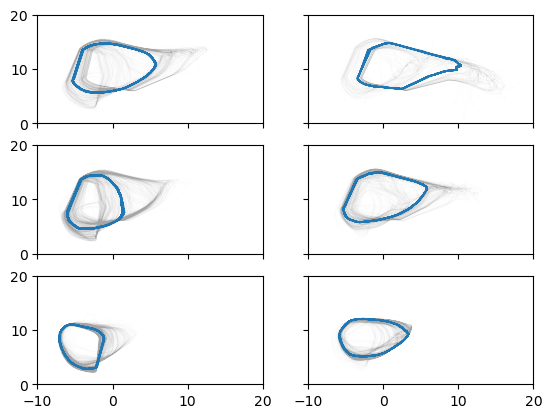

In [92]:
fig = plt.figure()
n1 = 1
for n in range(6):
    plt.subplot(3,2,n1)
    trk_len = int(len(embedding_all_prot)/9)
    trk_len_ode = int(len(embedding_all_prot_ode)/9)
    plt.plot(embedding_all_prot[n*trk_len:n1*trk_len,0], embedding_all_prot[n*trk_len:n1*trk_len,1], lw=0.01, alpha=0.7, c='gray')
    plt.plot(embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode,0], embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode,1], lw=1, alpha=1)

    plt.xlim(-10,20)
    plt.ylim(0, 20)

    ax = plt.gca()
    if (n1 % 2) == 0:
        ax.yaxis.set_tick_params(labelleft=False)
    if n1<5:
        ax.xaxis.set_tick_params(labelleft=False)
    n1 += 1

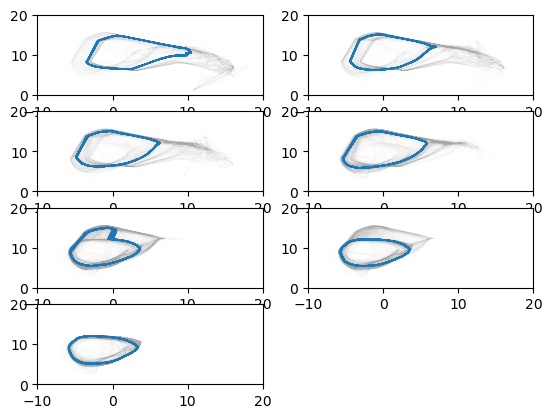

In [161]:
fig = plt.figure()
n1 = 8
fign = 1
for n in range(7,14):
    plt.subplot(4,2,fign)
    trk_len = int(len(embedding_all_prot)/14)
    trk_len_ode = int(len(embedding_all_prot_ode)/14)
    plt.plot(embedding_all_prot[n*trk_len:n1*trk_len,0], embedding_all_prot[n*trk_len:n1*trk_len,1], lw=0.01, alpha=0.7, c='gray')
    plt.plot(embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode,0], embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode,1], lw=1, alpha=1)

    plt.xlim(-10,20)
    plt.ylim(0, 20)

    ax = plt.gca()
#     if (n1 % 2) == 0:
#         ax.yaxis.set_tick_params(labelleft=False)
#     if n1<5:
#         ax.xaxis.set_tick_params(labelleft=False)
    n1 += 1
    fign += 1

In [38]:
trk_len = int(len(all_prot_tmp)/len(filenames_sp))
y_label_list = ['Skp2', 'p21', 'pp21', 'Cdh1', 'Myc', 'CycD', 'CycDp21', 'Rb', 'pRb', 'E2F', 'RbE2F',
                'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20']
dmso_050_prot_df = pd.DataFrame(all_prot_tmp[0*trk_len:1*trk_len,:])
dmso_050_time_df = pd.DataFrame(all_time_tmp[0*trk_len:1*trk_len,:])
dmso_050_emb_df = pd.DataFrame(embedding_all_prot[0*trk_len:1*trk_len,:])

dmso_007_prot_df = pd.DataFrame(all_prot_tmp[1*trk_len:2*trk_len,:])
dmso_007_time_df = pd.DataFrame(all_time_tmp[1*trk_len:2*trk_len,:])
dmso_007_emb_df = pd.DataFrame(embedding_all_prot[1*trk_len:2*trk_len,:])

dmso_023_prot_df = pd.DataFrame(all_prot_tmp[2*trk_len:3*trk_len,:])
dmso_023_time_df = pd.DataFrame(all_time_tmp[2*trk_len:3*trk_len,:])
dmso_023_emb_df = pd.DataFrame(embedding_all_prot[2*trk_len:3*trk_len,:])

dmso_045_prot_df = pd.DataFrame(all_prot_tmp[3*trk_len:4*trk_len,:])
dmso_045_time_df = pd.DataFrame(all_time_tmp[3*trk_len:4*trk_len,:])
dmso_045_emb_df = pd.DataFrame(embedding_all_prot[3*trk_len:4*trk_len,:])

dmso_085_prot_df = pd.DataFrame(all_prot_tmp[4*trk_len:5*trk_len,:])
dmso_085_time_df = pd.DataFrame(all_time_tmp[4*trk_len:5*trk_len,:])
dmso_085_emb_df = pd.DataFrame(embedding_all_prot[4*trk_len:5*trk_len,:])

erl_006_prot_df = pd.DataFrame(all_prot_tmp[5*trk_len:6*trk_len,:])
erl_006_time_df = pd.DataFrame(all_time_tmp[5*trk_len:6*trk_len,:])
erl_006_emb_df = pd.DataFrame(embedding_all_prot[5*trk_len:6*trk_len,:])

erl_076_prot_df = pd.DataFrame(all_prot_tmp[6*trk_len:7*trk_len,:])
erl_076_time_df = pd.DataFrame(all_time_tmp[6*trk_len:7*trk_len,:])
erl_076_emb_df = pd.DataFrame(embedding_all_prot[6*trk_len:7*trk_len,:])

erl_094_prot_df = pd.DataFrame(all_prot_tmp[7*trk_len:8*trk_len,:])
erl_094_time_df = pd.DataFrame(all_time_tmp[7*trk_len:8*trk_len,:])
erl_094_emb_df = pd.DataFrame(embedding_all_prot[7*trk_len:8*trk_len,:])

In [163]:
trk_len = int(len(all_prot_tmp)/14)
y_label_list = ['Skp2', 'p21', 'pp21', 'Cdh1', 'Myc', 'CycD', 'CycDp21', 'Rb', 'pRb', 'E2F', 'RbE2F',
                'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20']
erl_000_prot_df = pd.DataFrame(all_prot_tmp[7*trk_len:8*trk_len,:])
erl_000_time_df = pd.DataFrame(all_time_tmp[7*trk_len:8*trk_len,:])
erl_000_emb_df = pd.DataFrame(embedding_all_prot[7*trk_len:8*trk_len,:])

erl_020_prot_df = pd.DataFrame(all_prot_tmp[8*trk_len:9*trk_len,:])
erl_020_time_df = pd.DataFrame(all_time_tmp[8*trk_len:9*trk_len,:])
erl_020_emb_df = pd.DataFrame(embedding_all_prot[8*trk_len:9*trk_len,:])

erl_030_prot_df = pd.DataFrame(all_prot_tmp[9*trk_len:10*trk_len,:])
erl_030_time_df = pd.DataFrame(all_time_tmp[9*trk_len:10*trk_len,:])
erl_030_emb_df = pd.DataFrame(embedding_all_prot[9*trk_len:10*trk_len,:])

erl_050_prot_df = pd.DataFrame(all_prot_tmp[10*trk_len:11*trk_len,:])
erl_050_time_df = pd.DataFrame(all_time_tmp[10*trk_len:11*trk_len,:])
erl_050_emb_df = pd.DataFrame(embedding_all_prot[10*trk_len:11*trk_len,:])

erl_065_prot_df = pd.DataFrame(all_prot_tmp[11*trk_len:12*trk_len,:])
erl_065_time_df = pd.DataFrame(all_time_tmp[11*trk_len:12*trk_len,:])
erl_065_emb_df = pd.DataFrame(embedding_all_prot[11*trk_len:12*trk_len,:])

erl_070_prot_df = pd.DataFrame(all_prot_tmp[12*trk_len:13*trk_len,:])
erl_070_time_df = pd.DataFrame(all_time_tmp[12*trk_len:13*trk_len,:])
erl_070_emb_df = pd.DataFrame(embedding_all_prot[12*trk_len:13*trk_len,:])

erl_099_prot_df = pd.DataFrame(all_prot_tmp[13*trk_len:14*trk_len,:])
erl_099_time_df = pd.DataFrame(all_time_tmp[13*trk_len:14*trk_len,:])
erl_099_emb_df = pd.DataFrame(embedding_all_prot[13*trk_len:14*trk_len,:])

In [41]:
def restructProt(protDF, embedDF, timeDF):
    peaks_E, _ = find_peaks(protDF.iloc[:,int((win_len*11+win_len/2)-1)], prominence = 40/200, distance = 10)
    peaks_cdc, _ = find_peaks(protDF.iloc[:,int((win_len*17+win_len/2)-1)], prominence = 40/200, distance = 10)
    
    mit_win = pd.DataFrame()
    time_win = pd.DataFrame()
    umap_win = pd.DataFrame()
    num = 1
    
    for n in range(2,len(peaks_cdc)-3):   #make sure we have divisions at ends 
        tmp_mit = peaks_cdc[n]
        tmp_mit2 = peaks_cdc[n+1]
        tmp_mit3 = peaks_cdc[n+2]
        tmp_mit4 = peaks_cdc[n+3]
        
        tmp_g1_s = peaks_E[(tmp_mit < peaks_E) & (peaks_E < tmp_mit2)]
        tmp_g1_s_2 = peaks_E[(tmp_mit2 < peaks_E) & (peaks_E < tmp_mit3)]
        tmp_g1_s_3 = peaks_E[(tmp_mit3 < peaks_E) & (peaks_E < tmp_mit4)]    
             
        if (np.size(tmp_g1_s) > 0) & (np.size(tmp_g1_s_2)>0) & (np.size(tmp_g1_s_3)>0):
            ordered = [tmp_mit, tmp_g1_s[0], tmp_mit2, tmp_g1_s_2[0], tmp_mit3, tmp_g1_s_3[0], tmp_mit4]
            g1_len_tmp = np.array(timeDF.iloc[ordered[3],0]) - np.array(timeDF.iloc[[ordered[2]],0])
            tmp_prot = protDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp_umap = embedDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp_time = timeDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp = [g1_len_tmp]*len(tmp_time)
            tmp_g1s = [int(ordered[1])]*len(tmp_time)
            tmp_mit = [int(ordered[2])]*len(tmp_time)
            tmp_g1s2 = [int(ordered[3])]*len(tmp_time)
            tmp_mit2 = [int(ordered[4])]*len(tmp_time)
            
            tmp_time.insert(0, 'mit2', tmp_mit2)
            tmp_time.insert(0, 'G1-S_2', tmp_g1s2)
            tmp_time.insert(0, 'mit', tmp_mit)
            tmp_time.insert(0, 'G1-S', tmp_g1s)
            tmp_time.insert(0, 'G1_len', tmp)
            tmp_time.insert(0, 'div', [num]*len(tmp_time))
            num += 1
            
            mit_win = pd.concat([mit_win,tmp_prot],ignore_index=True)
            time_win = pd.concat([time_win, tmp_time], ignore_index=True)
            umap_win = pd.concat([umap_win, tmp_umap], ignore_index=True)
            
    return mit_win, time_win, umap_win

In [39]:
from scipy.signal import find_peaks
from numpy.linalg import norm
import multiprocess as mp
import time

In [97]:
mit_win_dmso_060, time_win_dmso_060, umap_win_dmso_060 = restructProt(dmso_060_prot_df, dmso_060_emb_df, dmso_060_time_df)
mit_win_dmso_065, time_win_dmso_065, umap_win_dmso_065 = restructProt(dmso_065_prot_df, dmso_065_emb_df, dmso_065_time_df)
mit_win_dmso_070, time_win_dmso_070, umap_win_dmso_070 = restructProt(dmso_070_prot_df, dmso_070_emb_df, dmso_070_time_df)

In [166]:
mit_win_dmso_000, time_win_dmso_000, umap_win_dmso_000 = restructProt(dmso_000_prot_df, dmso_000_emb_df, dmso_000_time_df)
mit_win_dmso_020, time_win_dmso_020, umap_win_dmso_020 = restructProt(dmso_020_prot_df, dmso_020_emb_df, dmso_020_time_df)
mit_win_dmso_030, time_win_dmso_030, umap_win_dmso_030 = restructProt(dmso_030_prot_df, dmso_030_emb_df, dmso_030_time_df)
mit_win_dmso_050, time_win_dmso_050, umap_win_dmso_050 = restructProt(dmso_050_prot_df, dmso_050_emb_df, dmso_050_time_df)
mit_win_dmso_065, time_win_dmso_065, umap_win_dmso_065 = restructProt(dmso_065_prot_df, dmso_065_emb_df, dmso_065_time_df)
mit_win_dmso_070, time_win_dmso_070, umap_win_dmso_070 = restructProt(dmso_070_prot_df, dmso_070_emb_df, dmso_070_time_df)
mit_win_dmso_099, time_win_dmso_099, umap_win_dmso_099 = restructProt(dmso_099_prot_df, dmso_099_emb_df, dmso_099_time_df)

In [167]:
mit_win_erl_000, time_win_erl_000, umap_win_erl_000 = restructProt(erl_000_prot_df, erl_000_emb_df, erl_000_time_df)
mit_win_erl_020, time_win_erl_020, umap_win_erl_020 = restructProt(erl_020_prot_df, erl_020_emb_df, erl_020_time_df)
mit_win_erl_030, time_win_erl_030, umap_win_erl_030 = restructProt(erl_030_prot_df, erl_030_emb_df, erl_030_time_df)
mit_win_erl_050, time_win_erl_050, umap_win_erl_050 = restructProt(erl_050_prot_df, erl_050_emb_df, erl_050_time_df)
mit_win_erl_065, time_win_erl_065, umap_win_erl_065 = restructProt(erl_065_prot_df, erl_065_emb_df, erl_065_time_df)
mit_win_erl_070, time_win_erl_070, umap_win_erl_070 = restructProt(erl_070_prot_df, erl_070_emb_df, erl_070_time_df)
mit_win_erl_099, time_win_erl_099, umap_win_erl_099 = restructProt(erl_099_prot_df, erl_099_emb_df, erl_099_time_df)

In [188]:
mit_win_dmso_050, time_win_dmso_050, umap_win_dmso_050 = restructProt(dmso_050_prot_df, dmso_050_emb_df, dmso_050_time_df)
mit_win_dmso_000, time_win_dmso_000, umap_win_dmso_000 = restructProt(dmso_000_prot_df, dmso_000_emb_df, dmso_000_time_df)
mit_win_dmso_030, time_win_dmso_030, umap_win_dmso_030 = restructProt(dmso_030_prot_df, dmso_030_emb_df, dmso_030_time_df)
mit_win_dmso_070, time_win_dmso_070, umap_win_dmso_070 = restructProt(dmso_070_prot_df, dmso_070_emb_df, dmso_070_time_df)
mit_win_dmso_099, time_win_dmso_099, umap_win_dmso_099 = restructProt(dmso_099_prot_df, dmso_099_emb_df, dmso_099_time_df)
mit_win_erl_000, time_win_erl_000, umap_win_erl_000 = restructProt(erl_000_prot_df, erl_000_emb_df, erl_000_time_df)
mit_win_erl_050, time_win_erl_050, umap_win_erl_050 = restructProt(erl_050_prot_df, erl_050_emb_df, erl_050_time_df)
mit_win_erl_099, time_win_erl_099, umap_win_erl_099 = restructProt(erl_099_prot_df, erl_099_emb_df, erl_099_time_df)

In [42]:
mit_win_dmso_050, time_win_dmso_050, umap_win_dmso_050 = restructProt(dmso_050_prot_df, dmso_050_emb_df, dmso_050_time_df)
mit_win_dmso_007, time_win_dmso_007, umap_win_dmso_007 = restructProt(dmso_007_prot_df, dmso_007_emb_df, dmso_007_time_df)
mit_win_dmso_023, time_win_dmso_023, umap_win_dmso_023 = restructProt(dmso_023_prot_df, dmso_023_emb_df, dmso_023_time_df)
mit_win_dmso_045, time_win_dmso_045, umap_win_dmso_045 = restructProt(dmso_045_prot_df, dmso_045_emb_df, dmso_045_time_df)
mit_win_dmso_085, time_win_dmso_085, umap_win_dmso_085 = restructProt(dmso_085_prot_df, dmso_085_emb_df, dmso_085_time_df)
mit_win_erl_006, time_win_erl_006, umap_win_erl_006 = restructProt(erl_006_prot_df, erl_006_emb_df, erl_006_time_df)
mit_win_erl_076, time_win_erl_076, umap_win_erl_076 = restructProt(erl_076_prot_df, erl_076_emb_df, erl_076_time_df)
mit_win_erl_094, time_win_erl_094, umap_win_erl_094 = restructProt(erl_094_prot_df, erl_094_emb_df, erl_094_time_df)

In [43]:
def calc_distances(ode_proj, ode_wind, stoch_proj, stoch_wind, time_win):
    all_d_proj = []
    for row in range(len(stoch_proj)):
        difs = [norm(stoch_proj.iloc[row].to_numpy() - ode_proj[n,:]) for n in range(len(ode_proj))]
        min_d = min(difs)
        all_d_proj.append(min_d)
        if (row%10000) == 0:
            print(row)
    
    all_d = []
#     for n in time_win['div'].unique():
#         tmpDF = time_win.loc[time_win['div'] == n]
#         tmp = np.array(stoch_wind.iloc[tmpDF.iloc[0,3]:tmpDF.iloc[0,5],:])
#         tmp_umap = np.array(umapDF.iloc[tmpDF.index[0]:tmpDF.index[-1],:])
    for row in range(len(stoch_wind)):
        difs = [norm(np.array(stoch_wind.iloc[row,:]) - ode_wind[n,:]) for n in range(len(ode_wind))]
        min_d = min(difs)
        all_d.append(min_d)
        if (row%10000) == 0:
            print(row)
        
    return all_d_proj, all_d

In [65]:
ode_proj_umap = embedding_all_prot_ode[7*trk_len_ode:7*trk_len_ode+200,:]
ode_wind = all_prot_tmp_ode_ab[7*trk_len_ode:7*trk_len_ode+200,:]
stoch_proj_umap = umap_win_dmso_050
stoch_wind = mit_win_dmso_050
time_win = time_win_dmso_050
rows = list(range(len(stoch_proj_umap)))


In [66]:
def calc_dis_proj_umap(row, stoch_proj_umap=stoch_proj_umap, ode_proj_umap=ode_proj_umap, norm=norm):
    difs = [norm(stoch_proj_umap.iloc[row].to_numpy() - ode_proj_umap[n,:]) for n in range(len(ode_proj_umap))]
    min_d = min(difs)
    return min_d

def calc_dis_win(row, stoch_wind=stoch_wind, ode_wind=ode_wind, norm=norm, np=np):
    difs = [norm(np.array(stoch_wind.iloc[row,:]) - ode_wind[n,:]) for n in range(len(ode_wind))]
    min_d = min(difs)
    return min_d

In [67]:
start = time.time()
with mp.Pool(processes = 12) as p:
    results_proj_d050_e094_umap = p.map(calc_dis_proj_umap, rows)

with mp.Pool(processes = 12) as p:
    results_d050_e094_wind = p.map(calc_dis_win, rows)
end = time.time()
print(end - start)


229.30099391937256


In [68]:
def plotDistHist(data, color='black', linewidth=1, bw=0.02, lim=6, label='DistHist'):
    xbins = np.arange(0, lim + bw, bw)
    
    _, _, his1= plt.hist(data, bins=xbins, color=color, linewidth=linewidth, histtype=u'step', 
                         density=True, label=label)
    return his1
def plotDistHistCDF(data, color='black', linewidth=1, bw=0.02, lim=6, label='DistHist'):
    xbins = np.arange(0, lim + bw, bw)
    
    _, _, his1= plt.hist(data, bins=xbins, color=color, linewidth=linewidth, histtype=u'step', density=True, 
                         cumulative=True, label=label)
    return his1

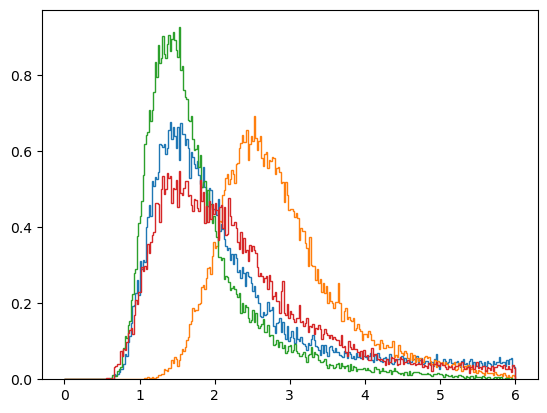

In [226]:
his1= plotDistHist(results_d050_d050_wind, color='tab:blue')
his1= plotDistHist(results_d050_e050_wind, color='tab:orange')
his1= plotDistHist(results_d050_d030_wind, color='tab:green')
his1= plotDistHist(results_d050_d070_wind, color='tab:red')




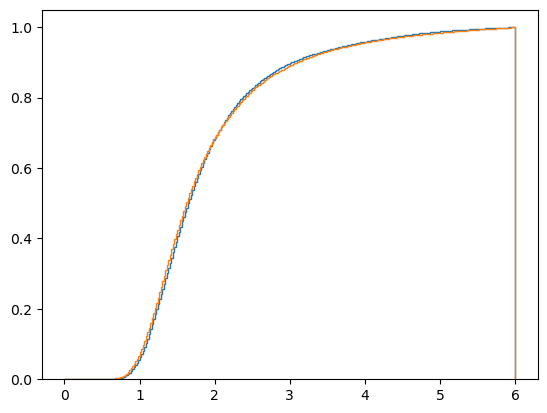

In [114]:
his1= plotDistHistCDF(results_d065_d060_wind, color='tab:blue')
his1= plotDistHistCDF(results_d065_d070_wind, color='tab:orange')



In [ ]:
his1= plotDistHistCDF(results_060_wind, color='blue')
his1= plotDistHistCDF(results_060_072_wind, color='green')



In [197]:
traj_dists = [results_e000_d000_wind, results_e000_e000_wind]
td_arr = np.array(traj_dists)

In [69]:
def close_traj(traj_dists):
    num_trajs = list(range(len(traj_dists)))
    td_arr = np.array(traj_dists)  
    mins = []
    min_vals = []
    
    for traj in range(td_arr.shape[1]):
        mins.append(np.argmin(td_arr[:,traj]))
        min_vals.append(np.amin(td_arr[:,traj]))
        
    return mins, min_vals
            

In [320]:
test, test_vals = close_traj(traj_dists)

In [200]:
stoch_proj_umap['Closest'] = test

In [ ]:
stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 0]

In [227]:
fig = plt.figure()
trk_len = int(len(embedding_all_prot)/14)
trk_len_ode = int(len(embedding_all_prot_ode)/14)
embedding_tmp = embedding_all_prot[0*trk_len:1*trk_len,:]
stoch_d00 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 0]
stoch_e00 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 1]
plt.scatter(stoch_d00[0], stoch_d00[1], s=0.2, alpha=0.1)
plt.scatter(stoch_e00[0], stoch_e00[1], s=0.2, alpha=0.1)
# plt.plot(embedding_all_prot[6*trk_len:7*trk_len,0], embedding_all_prot[6*trk_len:7*trk_len,1], lw=0.01, alpha=0.7, c='gray')
# plt.plot(embedding_all_prot_ode[6*trk_len_ode:7*trk_len_ode,0], embedding_all_prot_ode[6*trk_len_ode:7*trk_len_ode,1], lw=1, alpha=1)
plt.plot(embedding_all_prot_ode[0*trk_len_ode:1*trk_len_ode,0], embedding_all_prot_ode[0*trk_len_ode:1*trk_len_ode,1], lw=0.1, alpha=1)
plt.plot(embedding_all_prot_ode[7*trk_len_ode:8*trk_len_ode,0], embedding_all_prot_ode[7*trk_len_ode:8*trk_len_ode,1], lw=0.1, alpha=1)


plt.xlim(-10,20)
plt.ylim(0, 20)

KeyError: 'Closest'

<Figure size 640x480 with 0 Axes>

In [202]:
len(stoch_d00)

2168

In [75]:
traj_dists = [results_d050_d050_wind, results_d050_d007_wind, results_d050_d023_wind, 
              results_d050_d045_wind, results_d050_d085_wind, results_d050_e006_wind,
              results_d050_e076_wind, results_d050_e094_wind]
td_arr = np.array(traj_dists)


In [77]:
test, test_vals = close_traj(traj_dists)


In [78]:
stoch_proj_umap['Closest'] = test

(0.0, 20.0)

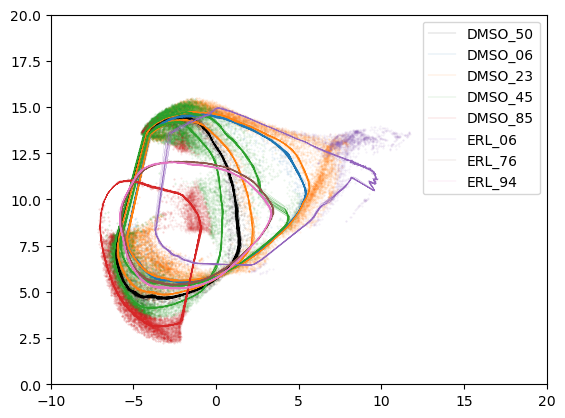

In [80]:
fig = plt.figure()
trk_len = int(len(embedding_all_prot)/len(filenames_sp))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_sp))

stoch_d50 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 0]

stoch_d07 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 1]
stoch_d23 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 2]
stoch_d45 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 3]
stoch_d85 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 4]
stoch_e06 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 5]
stoch_e76 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 6]
stoch_e94 = stoch_proj_umap.loc[stoch_proj_umap['Closest'] == 7]

plt.scatter(stoch_d50[0], stoch_d50[1], s=0.2, alpha=0.1, color='black')

plt.scatter(stoch_d07[0], stoch_d07[1], s=0.2, alpha=0.1)
plt.scatter(stoch_d23[0], stoch_d23[1], s=0.2, alpha=0.1)
plt.scatter(stoch_d45[0], stoch_d45[1], s=0.2, alpha=0.1)
plt.scatter(stoch_d85[0], stoch_d85[1], s=0.2, alpha=0.1)
plt.scatter(stoch_e06[0], stoch_e06[1], s=0.2, alpha=0.1)
plt.scatter(stoch_e76[0], stoch_e76[1], s=0.2, alpha=0.1)
plt.scatter(stoch_e94[0], stoch_e94[1], s=0.2, alpha=0.1)

# plt.plot(embedding_all_prot[6*trk_len:7*trk_len,0], embedding_all_prot[6*trk_len:7*trk_len,1], lw=0.01, alpha=0.7, c='gray')
# plt.plot(embedding_all_prot_ode[6*trk_len_ode:7*trk_len_ode,0], embedding_all_prot_ode[6*trk_len_ode:7*trk_len_ode,1], lw=1, alpha=1)
plt.plot(embedding_all_prot_ode[0*trk_len_ode:1*trk_len_ode,0], embedding_all_prot_ode[0*trk_len_ode:1*trk_len_ode,1], lw=0.1, alpha=1, color='black', label='DMSO_50')

plt.plot(embedding_all_prot_ode[1*trk_len_ode:2*trk_len_ode,0], embedding_all_prot_ode[1*trk_len_ode:2*trk_len_ode,1], lw=0.1, alpha=1, label='DMSO_06')
plt.plot(embedding_all_prot_ode[2*trk_len_ode:3*trk_len_ode,0], embedding_all_prot_ode[2*trk_len_ode:3*trk_len_ode,1], lw=0.1, alpha=1, label='DMSO_23')
plt.plot(embedding_all_prot_ode[3*trk_len_ode:4*trk_len_ode,0], embedding_all_prot_ode[3*trk_len_ode:4*trk_len_ode,1], lw=0.1, alpha=1, label='DMSO_45')
plt.plot(embedding_all_prot_ode[4*trk_len_ode:5*trk_len_ode,0], embedding_all_prot_ode[4*trk_len_ode:5*trk_len_ode,1], lw=0.1, alpha=1, label='DMSO_85')
plt.plot(embedding_all_prot_ode[5*trk_len_ode:6*trk_len_ode,0], embedding_all_prot_ode[5*trk_len_ode:6*trk_len_ode,1], lw=0.1, alpha=1, label='ERL_06')
plt.plot(embedding_all_prot_ode[6*trk_len_ode:7*trk_len_ode,0], embedding_all_prot_ode[6*trk_len_ode:7*trk_len_ode,1], lw=0.1, alpha=1, label='ERL_76')
plt.plot(embedding_all_prot_ode[7*trk_len_ode:8*trk_len_ode,0], embedding_all_prot_ode[7*trk_len_ode:8*trk_len_ode,1], lw=0.1, alpha=1, label='ERL_94')

plt.legend()
plt.xlim(-10,20)
plt.ylim(0, 20)

In [81]:
len(stoch_d50)

4909

In [82]:
len(stoch_d07)

2133

In [85]:
len(stoch_d23)

16503

In [86]:
len(stoch_d45)

20154

In [87]:
len(stoch_d85)

9164

In [88]:
len(stoch_e06)

2019

In [89]:
len(stoch_e76)

88

In [90]:
len(stoch_e94)

64

In [322]:
min7 = test_vals

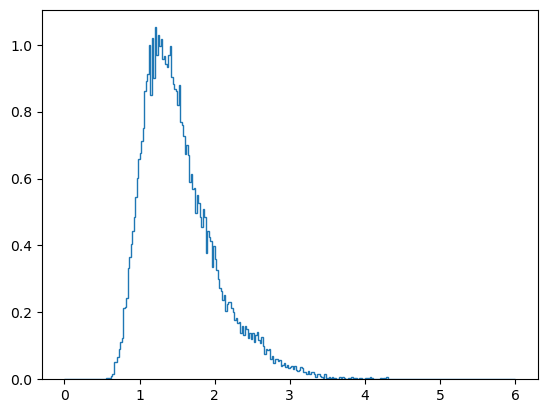

In [326]:
his1= plotDistHist(min7, color='tab:blue')

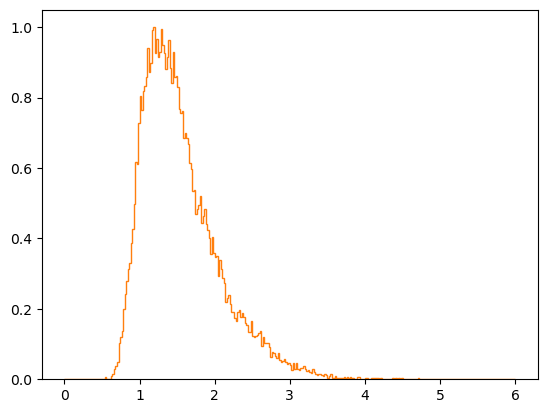

In [91]:
his1= plotDistHist(test_vals, color='tab:orange')